# Aircraft Engine Remaining Useful Life Prediction
**NASA C-MAPSS FD001–FD004 | Machine Learning Laboratory**

Md. Muhiminul Islam | 0812310205101006

## 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

## 2. Load Four Datasets
Training and official labeled endpoint test data are read directly from the data folder.

In [4]:
train_1 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\train_FD001.csv")
train_2 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\train_FD002.csv")
train_3 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\train_FD003.csv")
train_4 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\train_FD004.csv")

test_1 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\test_last_cycle_FD001_labeled.csv")
test_2 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\test_last_cycle_FD002_labeled.csv")
test_3 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\test_last_cycle_FD003_labeled.csv")
test_4 = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\test_last_cycle_FD004_labeled.csv")

print('FD001:', train_1.shape, test_1.shape)
print('FD002:', train_2.shape, test_2.shape)
print('FD003:', train_3.shape, test_3.shape)
print('FD004:', train_4.shape, test_4.shape)

FD001: (20631, 27) (100, 27)
FD002: (53759, 27) (259, 27)
FD003: (24720, 27) (100, 27)
FD004: (61249, 27) (248, 27)


## 3. Check the Data

In [5]:
datasets = {'FD001': (train_1, test_1), 'FD002': (train_2, test_2),
            'FD003': (train_3, test_3), 'FD004': (train_4, test_4)}

for name, (train, _) in datasets.items():
    last_cycle = train.groupby('engine_id')['cycle'].transform('max')
    calculated_rul = last_cycle - train['cycle']

    engines = train['engine_id'].nunique()
    missing = train.isnull().sum().sum()
    duplicates = train.duplicated(['engine_id', 'cycle']).sum()
    rul_matches = (calculated_rul == train['RUL']).all()

    print(name, '| Engines:', engines, '| Missing:', missing,
          '| Duplicates:', duplicates, '| RUL matches:', rul_matches)

FD001 Engines: 100 Missing: 0 Duplicates: 0 RUL correct: True
FD002 Engines: 260 Missing: 0 Duplicates: 0 RUL correct: True
FD003 Engines: 100 Missing: 0 Duplicates: 0 RUL correct: True
FD004 Engines: 249 Missing: 0 Duplicates: 0 RUL correct: True


## 4. RUL Distribution

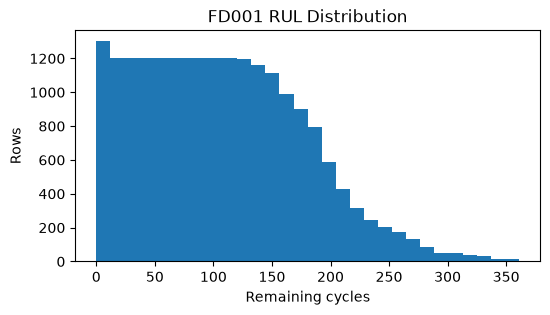

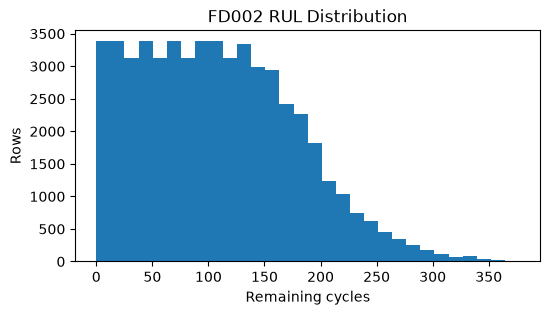

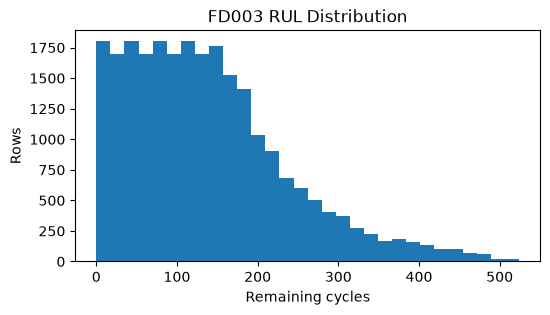

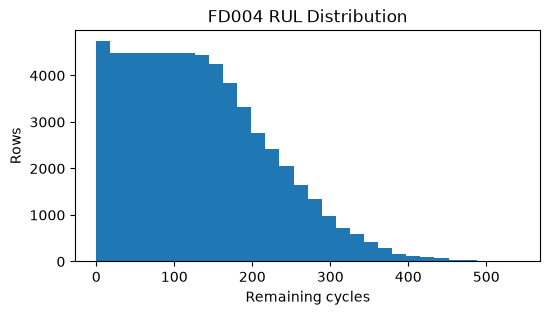

In [6]:
for name, (df, test) in datasets.items():
    plt.figure(figsize=(6, 3))
    plt.hist(df['RUL'], bins=30)
    plt.title(name + ' RUL Distribution')
    plt.xlabel('Remaining cycles')
    plt.ylabel('Rows')
    plt.show()

## 5. Regression Models
Seven standard supervised regression models are compared. Scaling is fitted using only training engines.

In [ ]:
models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=80, max_depth=3, random_state=42),
    'SVR': make_pipeline(StandardScaler(), SVR(C=100, epsilon=10)),
}
try:
    from xgboost import XGBRegressor # pyright: ignore[reportMissingImports]
    models['XGBoost'] = XGBRegressor(n_estimators=80, max_depth=4, learning_rate=0.1, n_jobs=2, random_state=42)
except ImportError:
    print('XGBoost not installed; the other six models will run.')

XGBoost not installed; the other six models will run.


## 6. Separate Engine-wise Validation and Model Comparison
Each dataset is split by engine, not by individual rows.

In [8]:
validation_tables = []
endpoint_tables = []
test_tables = []
significance_tables = []
cv_tables = []
trained_models = {}

for name, (df, test) in datasets.items():
    print('\\nDATASET:', name)
    features = df.drop(columns=['engine_id', 'RUL']).columns
    features = [col for col in features if df[col].nunique() > 1]
    X = df[features]
    y = df['RUL']
    groups = df['engine_id']

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    train_idx, val_idx = next(splitter.split(X, y, groups))
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    val_engines = groups.iloc[val_idx]

    results = []
    predictions = {}
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        pred = np.maximum(0, model.predict(X_val))
        predictions[model_name] = pred
        results.append([name, model_name,
                        mean_absolute_error(y_val, pred),
                        np.sqrt(mean_squared_error(y_val, pred)),
                        r2_score(y_val, pred)])

    comparison = pd.DataFrame(results, columns=['Dataset', 'Model', 'MAE', 'RMSE', 'R2'])
    comparison = comparison.sort_values('RMSE')
    validation_tables.append(comparison)
    display(comparison.round(3))
    best_name = comparison.iloc[0]['Model']
    best_model = models[best_name]
    best_pred = predictions[best_name]
    print('Best validation model:', best_name)

    near = y_val <= 30
    print('Near-failure MAE:', round(mean_absolute_error(y_val[near], best_pred[near]), 3))

    engine_errors = pd.DataFrame({'engine_id': val_engines.to_numpy()})
    for model_name, pred in predictions.items():
        engine_errors[model_name] = np.abs(y_val.to_numpy() - pred)
    engine_errors = engine_errors.groupby('engine_id').mean()
    t_rows = []
    for model_name in models:
        if model_name != best_name:
            t_stat, p_value = ttest_rel(engine_errors[best_name], engine_errors[model_name])
            t_rows.append([name, best_name, model_name, t_stat, p_value])
    t_table = pd.DataFrame(t_rows, columns=['Dataset', 'Best Model', 'Compared With', 't-statistic', 'p-value'])
    if len(t_table):
        t_table['Adjusted p'] = multipletests(t_table['p-value'], method='holm')[1]
        t_table['Significant (0.05)'] = t_table['Adjusted p'] < 0.05
    significance_tables.append(t_table)

    cv = GroupKFold(n_splits=3)
    scores = cross_val_score(clone(best_model), X_train, y_train,
                             groups=groups.iloc[train_idx], cv=cv,
                             scoring='neg_mean_squared_error', n_jobs=1)
    cv_tables.append([name, best_name, np.sqrt(-scores).mean()])

    margin = np.quantile(np.abs(y_val.to_numpy() - best_pred), 0.90)
    val_coverage = np.mean(np.abs(y_val.to_numpy() - best_pred) <= margin)
    final_model = clone(best_model)
    final_model.fit(X, y)
    final_pred = np.maximum(0, final_model.predict(test[features]))
    trained_models[name] = (final_model, features, margin)
    endpoint_tables.append([name, best_name,
                            mean_absolute_error(test['RUL'], final_pred),
                            np.sqrt(mean_squared_error(test['RUL'], final_pred)),
                            r2_score(test['RUL'], final_pred),
                            np.mean(np.abs(test['RUL'].to_numpy() - final_pred) <= margin)])
    test_tables.append(pd.DataFrame({'Dataset': name, 'engine_id': test['engine_id'],
                                      'Actual RUL': test['RUL'],
                                      'Predicted RUL': np.round(final_pred, 2),
                                      'Lower': np.maximum(0, final_pred - margin).round(2),
                                      'Upper': (final_pred + margin).round(2)}))
    print('Validation interval coverage:', round(val_coverage, 3))

\nDATASET: FD001


,Dataset,Model,MAE,RMSE,R2
5,FD001,SVR,22.471,29.566,0.797
4,FD001,Gradient Boosting,22.641,29.658,0.796
3,FD001,Random Forest,23.634,31.086,0.776
0,FD001,Linear Regression,24.504,31.272,0.773
1,FD001,Ridge,24.505,31.274,0.773
2,FD001,Decision Tree,25.095,32.768,0.751


Best validation model: SVR
Near-failure MAE: 6.369
Validation interval coverage: 0.9
\nDATASET: FD002


,Dataset,Model,MAE,RMSE,R2
5,FD002,SVR,24.380,33.567,0.740
3,FD002,Random Forest,26.294,35.149,0.715
4,FD002,Gradient Boosting,27.595,36.007,0.701
0,FD002,Linear Regression,29.704,37.349,0.678
1,FD002,Ridge,29.952,37.594,0.674
2,FD002,Decision Tree,29.119,38.228,0.662


Best validation model: SVR
Near-failure MAE: 11.368
Validation interval coverage: 0.9
\nDATASET: FD003


,Dataset,Model,MAE,RMSE,R2
5,FD003,SVR,34.897,53.448,0.668
4,FD003,Gradient Boosting,35.732,54.807,0.651
1,FD003,Ridge,40.073,56.564,0.628
0,FD003,Linear Regression,40.074,56.566,0.628
3,FD003,Random Forest,36.123,57.106,0.621
2,FD003,Decision Tree,38.369,58.825,0.597


Best validation model: SVR
Near-failure MAE: 5.861
Validation interval coverage: 0.9
\nDATASET: FD004


,Dataset,Model,MAE,RMSE,R2
3,FD004,Random Forest,41.144,55.770,0.605
5,FD004,SVR,42.090,56.316,0.597
4,FD004,Gradient Boosting,44.155,57.552,0.579
1,FD004,Ridge,45.544,57.913,0.574
0,FD004,Linear Regression,45.775,58.278,0.568
2,FD004,Decision Tree,44.721,59.291,0.553


Best validation model: Random Forest
Near-failure MAE: 9.436
Validation interval coverage: 0.9


## 7. Overall Validation Comparison

Dataset,FD001,FD002,FD003,FD004
Model,,,,
Decision Tree,32.77,38.23,58.83,59.29
Gradient Boosting,29.66,36.01,54.81,57.55
Linear Regression,31.27,37.35,56.57,58.28
Random Forest,31.09,35.15,57.11,55.77
Ridge,31.27,37.59,56.56,57.91
SVR,29.57,33.57,53.45,56.32


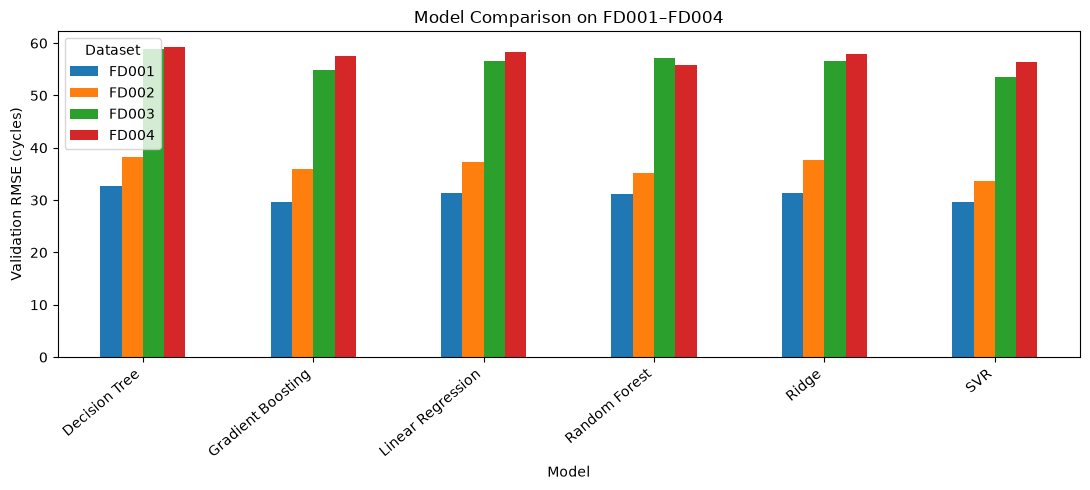

In [9]:
validation = pd.concat(validation_tables, ignore_index=True)
display(validation.pivot(index='Model', columns='Dataset', values='RMSE').round(2))
validation.pivot(index='Model', columns='Dataset', values='RMSE').plot(kind='bar', figsize=(11, 5))
plt.ylabel('Validation RMSE (cycles)')
plt.title('Model Comparison on FD001–FD004')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

## 8. Grouped Cross-Validation
Three-fold cross-validation is performed on the selected model in each training subset.

In [10]:
cv_results = pd.DataFrame(cv_tables, columns=['Dataset', 'Best Model', 'Mean CV RMSE'])
display(cv_results.round(3))

,Dataset,Best Model,Mean CV RMSE
0,FD001,SVR,39.681
1,FD002,SVR,39.164
2,FD003,SVR,62.383
3,FD004,Random Forest,50.687


## 9. Paired t-Test and Statistical Significance
Paired tests use one mean absolute error per validation engine. Holm correction controls multiple comparisons within each subset.

In [11]:
significance = pd.concat(significance_tables, ignore_index=True)
display(significance.round(4))

,Dataset,Best Model,Compared With,t-statistic,p-value,Adjusted p,Significant (0.05)
0,FD001,SVR,Linear Regression,-1.6931,0.1068,0.4271,False
1,FD001,SVR,Ridge,-1.6931,0.1068,0.4271,False
2,FD001,SVR,Decision Tree,-3.3242,0.0036,0.0178,True
3,FD001,SVR,Random Forest,-1.5148,0.1463,0.4271,False
4,FD001,SVR,Gradient Boosting,-0.6587,0.5180,0.5180,False
5,FD002,SVR,Linear Regression,-6.5895,0.0000,0.0000,True
6,FD002,SVR,Ridge,-7.1630,0.0000,0.0000,True
7,FD002,SVR,Decision Tree,-6.8516,0.0000,0.0000,True
8,FD002,SVR,Random Forest,-3.6681,0.0006,0.0006,True
9,FD002,SVR,Gradient Boosting,-4.9845,0.0000,0.0000,True


## 10. Official Test Results
Official test labels are used only after the best model is selected on validation data.

In [12]:
final_results = pd.DataFrame(endpoint_tables, columns=['Dataset', 'Selected Model', 'MAE', 'RMSE', 'R2', 'Interval Coverage'])
display(final_results.round(3))

,Dataset,Selected Model,MAE,RMSE,R2,Interval Coverage
0,FD001,SVR,17.762,24.024,0.666,0.970
1,FD002,SVR,21.133,28.126,0.726,0.927
2,FD003,SVR,24.782,37.919,0.161,0.950
3,FD004,Random Forest,28.632,39.545,0.474,0.964


## 11. Actual vs Predicted RUL

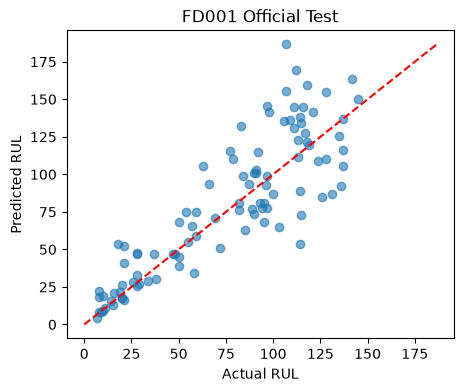

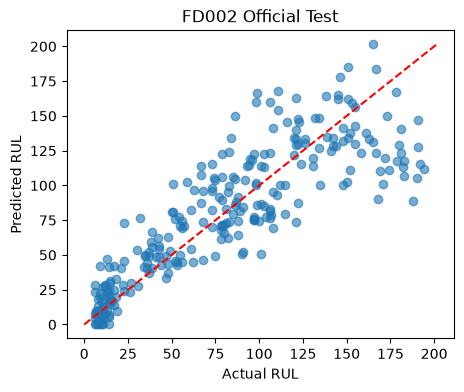

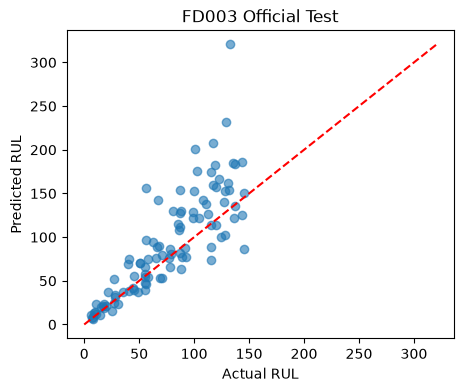

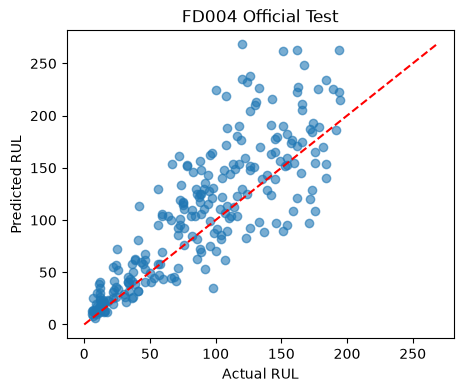

In [13]:
test_predictions = pd.concat(test_tables, ignore_index=True)
for name in datasets:
    df_plot = test_predictions[test_predictions['Dataset'] == name]
    plt.figure(figsize=(5, 4))
    plt.scatter(df_plot['Actual RUL'], df_plot['Predicted RUL'], alpha=0.6)
    limit = max(df_plot['Actual RUL'].max(), df_plot['Predicted RUL'].max())
    plt.plot([0, limit], [0, limit], 'r--')
    plt.xlabel('Actual RUL')
    plt.ylabel('Predicted RUL')
    plt.title(name + ' Official Test')
    plt.show()

## 12. Sensor Trends

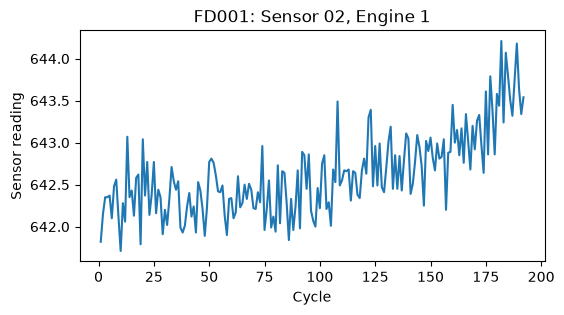

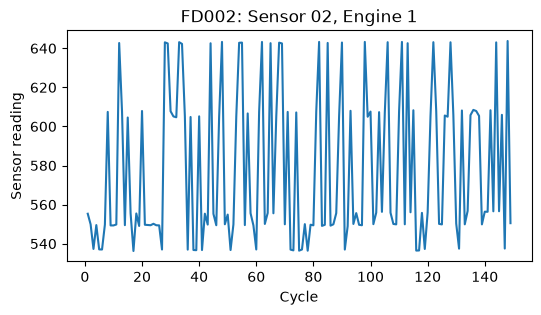

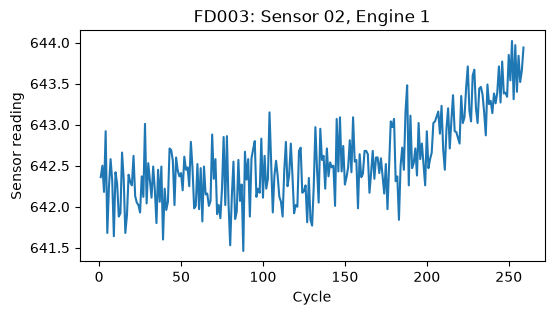

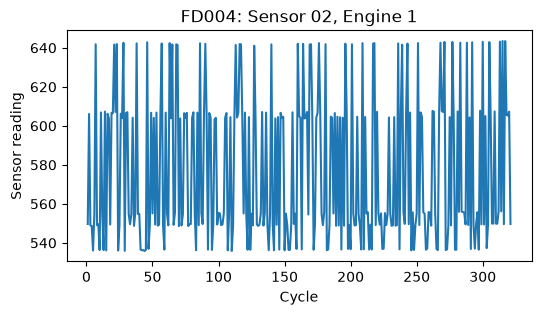

In [14]:
for name, (df, test) in datasets.items():
    engine = df[df['engine_id'] == 1]
    plt.figure(figsize=(6, 3))
    plt.plot(engine['cycle'], engine['sensor_02'])
    plt.title(name + ': Sensor 02, Engine 1')
    plt.xlabel('Cycle')
    plt.ylabel('Sensor reading')
    plt.show()

## 13. Feature Importance

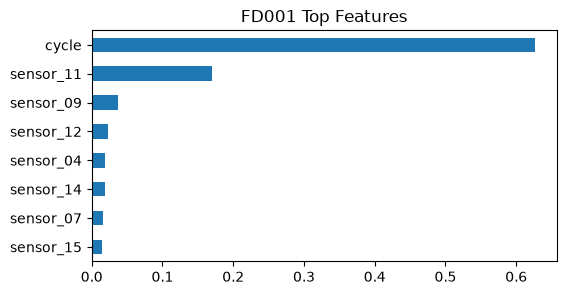

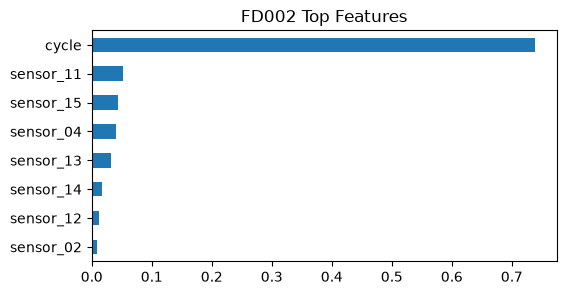

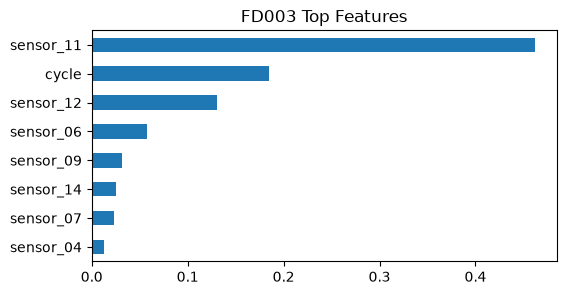

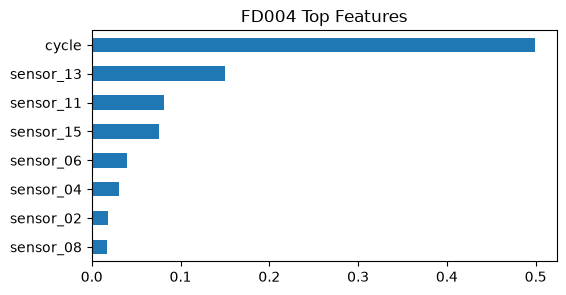

In [15]:
for name, (df, test) in datasets.items():
    forest = clone(models['Random Forest'])
    features = trained_models[name][1]
    forest.fit(df[features], df['RUL'])
    importance = pd.Series(forest.feature_importances_, index=features).nlargest(8).sort_values()
    importance.plot.barh(figsize=(6, 3), title=name + ' Top Features')
    plt.show()

## 14. Predict RUL from a CSV
Choose the dataset that matches the operating conditions and failure modes of the input readings.

In [18]:
new_data = pd.read_csv(r"C:\Users\muhai\Desktop\Semesters\41\ML_Lab_Project\notebooks\data\train_FD001.csv")
model, features, margin = trained_models['FD001']
new_data['Predicted_RUL'] = np.maximum(0, model.predict(new_data[features])).round(2)
new_data['Lower_RUL'] = np.maximum(0, new_data['Predicted_RUL'] - margin).round(2)
new_data['Upper_RUL'] = (new_data['Predicted_RUL'] + margin).round(2)
display(new_data[['engine_id', 'cycle', 'Predicted_RUL', 'Lower_RUL', 'Upper_RUL']].head())

,engine_id,cycle,Predicted_RUL,Lower_RUL,Upper_RUL
0,1,1,195.15,143.15,247.15
1,1,2,199.70,147.70,251.70
2,1,3,205.50,153.50,257.50
3,1,4,189.93,137.93,241.93
4,1,5,192.53,140.53,244.53


## Conclusion
Four C-MAPSS subsets are evaluated independently using engine-wise validation, regression metrics, cross-validation and paired t-tests. Results are from simulated engines, not certified aircraft maintenance predictions.